In [69]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

**MEAN**

In [70]:
rng = np.random.default_rng(42)

K = 5
N = 2000

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

means_0 = np.array([
    [-4.0, -3.0],
    [-2.0,  2.0],
    [ 0.0, -1.0],
    [ 2.0,  3.0],
    [ 4.0, -2.0]
])

means_1 = np.array([
    [-4.0,  3.0],
    [-2.0, -2.0],
    [ 0.0,  4.0],
    [ 2.0, -3.0],
    [ 4.0,  2.0]
])

**MATRIX FOR ALL COVARIANCES**

In [71]:
covariance_types = {
    "Isotropic": [
        1.0 * np.eye(2),
        0.8 * np.eye(2),
        1.2 * np.eye(2),
        0.6 * np.eye(2),
        1.5 * np.eye(2)
    ],

    "Diagonal": [
        np.array([[1.5, 0.0],
                  [0.0, 0.4]]),

        np.array([[0.5, 0.0],
                  [0.0, 1.5]]),

        np.array([[1.2, 0.0],
                  [0.0, 0.6]]),

        np.array([[0.8, 0.0],
                  [0.0, 1.8]]),

        np.array([[2.0, 0.0],
                  [0.0, 0.7]])
    ],

    "Full": [
        np.array([[1.5, 0.8],
                  [0.8, 1.0]]),

        np.array([[1.2, -0.6],
                  [-0.6, 1.0]]),

        np.array([[0.8, 0.3],
                  [0.3, 1.4]]),

        np.array([[1.5, -0.5],
                  [-0.5, 0.8]]),

        np.array([[1.0, 0.6],
                  [0.6, 1.5]])
    ]
}

**CALCULATING GAUSSIAN DENSITY AND GENERATING GMM DATA**

In [72]:

def gaussian_density(x, mean, covariance):
    d = len(mean)
    diff = x - mean

    det = np.linalg.det(covariance)
    inv = np.linalg.inv(covariance)

    exponent = -0.5 * diff.T @ inv @ diff

    coefficient = 1 / (
        (2 * np.pi) ** (d / 2) * np.sqrt(det)
    )

    return coefficient * np.exp(exponent)


def generate_gmm_data(means, covariances, n_samples):
    component_ids = rng.choice(
        K, size=n_samples, p=weights
    )

    X = np.zeros((n_samples, len(means[0])))

    for j in range(n_samples):
        i = component_ids[j]

        X[j] = rng.multivariate_normal(
            means[i], covariances[i]
        )

        density = gaussian_density(
            X[j], means[i], covariances[i]
        )

    return X, component_ids

In [73]:
def plot_generated_data(X0, comp0, X1, comp1, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(
        X0[:, 0], X0[:, 1],
        c=comp0, cmap="viridis", s=12
    )
    axes[0].set_title("Class 0: Gaussian components")
    axes[0].set_xlabel("x1")
    axes[0].set_ylabel("x2")

    axes[1].scatter(
        X1[:, 0], X1[:, 1],
        c=comp1, cmap="viridis", s=12
    )
    axes[1].set_title("Class 1: Gaussian components")
    axes[1].set_xlabel("x1")
    axes[1].set_ylabel("x2")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()




In [74]:
def plot_kmeans_boundaries(X, model, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    regions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(
        xx, yy, regions,
        alpha=0.20, cmap="viridis"
    )

    cluster_ids = model.predict(X)

    plt.scatter(
        X[:, 0], X[:, 1],
        c=cluster_ids, cmap="viridis", s=12
    )

    centers = model.cluster_centers_

    plt.scatter(
        centers[:, 0], centers[:, 1],
        c="red", marker="X", s=150,
        edgecolors="black", label="Centroids"
    )

    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.show()



**CALCULATE DISTORTION**

In [75]:
def calculate_distortion(X, model):
    distances = model.transform(X)
    squared_distances = distances ** 2

    cluster_ids = model.predict(X)

    distortion = squared_distances[
        np.arange(len(X)), cluster_ids
    ]

    return distortion

In [76]:
for covariance_name, covariances in covariance_types.items():

    print("\nCovariance type:", covariance_name)

    X0, comp0 = generate_gmm_data(
        means_0, covariances, N
    )

    X1, comp1 = generate_gmm_data(
        means_1, covariances, N
    )

    print("Class 0 data shape:", X0.shape)
    print("Class 1 data shape:", X1.shape)


Covariance type: Isotropic
Class 0 data shape: (2000, 2)
Class 1 data shape: (2000, 2)

Covariance type: Diagonal
Class 0 data shape: (2000, 2)
Class 1 data shape: (2000, 2)

Covariance type: Full
Class 0 data shape: (2000, 2)
Class 1 data shape: (2000, 2)


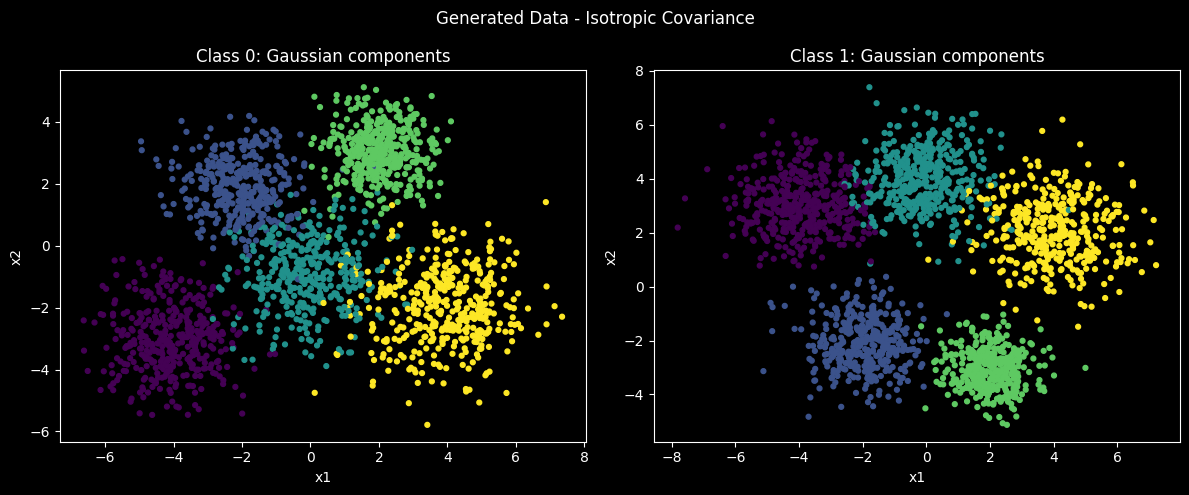

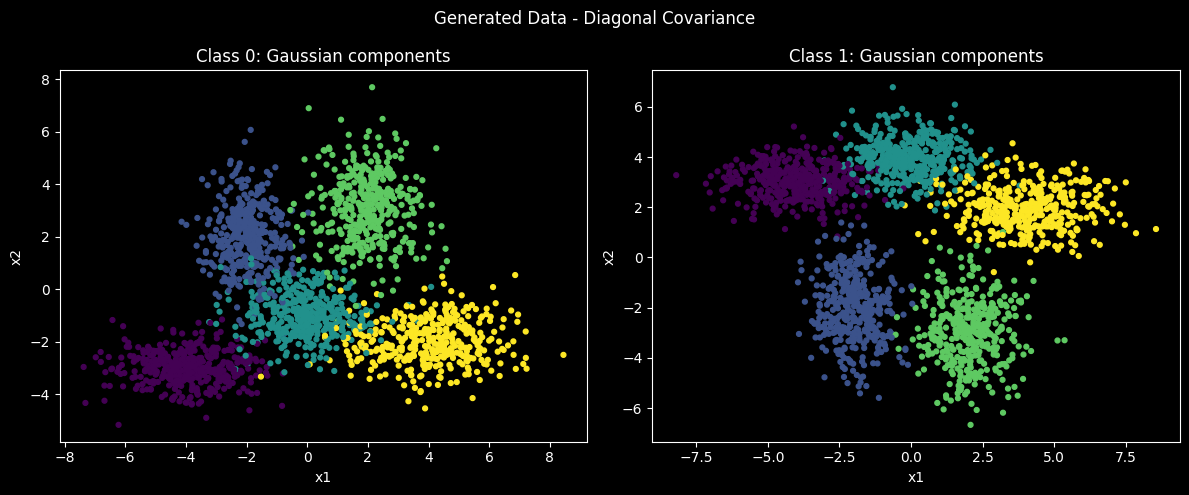

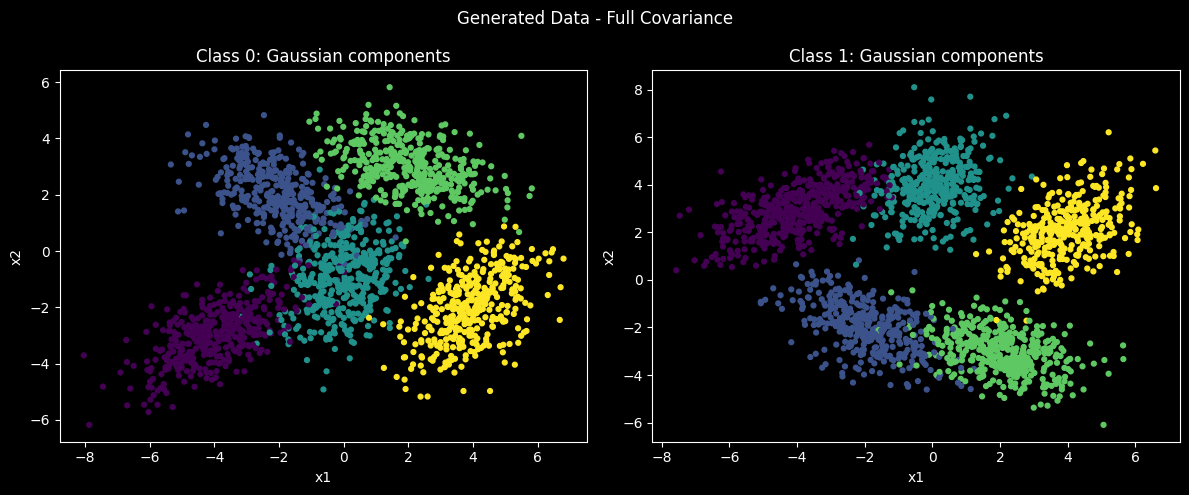

In [77]:
for covariance_name, covariances in covariance_types.items():

    X0, comp0 = generate_gmm_data(
        means_0, covariances, N
    )

    X1, comp1 = generate_gmm_data(
        means_1, covariances, N
    )

    plot_generated_data(
        X0, comp0, X1, comp1,
        f"Generated Data - {covariance_name} Covariance"
    )

**SPLITTING DATA**

In [78]:
for covariance_name, covariances in covariance_types.items():

    X0, _ = generate_gmm_data(means_0, covariances, N)
    X1, _ = generate_gmm_data(means_1, covariances, N)

    X0_train, X0_test = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, X1_test = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    print("\nCovariance:", covariance_name)
    print("Class 0 training:", X0_train.shape)
    print("Class 0 testing:", X0_test.shape)
    print("Class 1 training:", X1_train.shape)
    print("Class 1 testing:", X1_test.shape)


Covariance: Isotropic
Class 0 training: (1600, 2)
Class 0 testing: (400, 2)
Class 1 training: (1600, 2)
Class 1 testing: (400, 2)

Covariance: Diagonal
Class 0 training: (1600, 2)
Class 0 testing: (400, 2)
Class 1 training: (1600, 2)
Class 1 testing: (400, 2)

Covariance: Full
Class 0 training: (1600, 2)
Class 0 testing: (400, 2)
Class 1 training: (1600, 2)
Class 1 testing: (400, 2)


**K MEANS CLUSTERING**

In [79]:
for covariance_name, covariances in covariance_types.items():

    X0, _ = generate_gmm_data(means_0, covariances, N)
    X1, _ = generate_gmm_data(means_1, covariances, N)

    X0_train, _ = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, _ = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    model0 = KMeans(
        n_clusters=K, random_state=42, n_init=10
    )

    model1 = KMeans(
        n_clusters=K, random_state=42, n_init=10
    )

    model0.fit(X0_train)
    model1.fit(X1_train)

    print("\nCovariance:", covariance_name)
    print("Class 0 centroids:\n", model0.cluster_centers_)
    print("Class 1 centroids:\n", model1.cluster_centers_)


Covariance: Isotropic
Class 0 centroids:
 [[-1.99209581  1.9298293 ]
 [ 4.25048066 -2.05861875]
 [-4.0269031  -3.00854655]
 [ 0.01073037 -1.14874538]
 [ 2.02815011  2.98053335]]
Class 1 centroids:
 [[-2.00196089 -2.08553769]
 [ 4.08304668  1.92980825]
 [ 1.92372821 -3.01711822]
 [ 0.05057966  4.13338611]
 [-3.89829453  2.94623166]]

Covariance: Diagonal
Class 0 centroids:
 [[ 1.93786859  3.23453396]
 [ 0.17931444 -1.02924937]
 [ 4.24011561 -2.01208608]
 [-4.00872264 -2.98728193]
 [-2.02760043  2.06613138]]
Class 1 centroids:
 [[ 0.01678928  3.91642759]
 [ 2.04287618 -3.11577138]
 [-4.07306921  2.98233085]
 [-1.98797423 -1.98826814]
 [ 3.88491843  1.92304445]]

Covariance: Full
Class 0 centroids:
 [[-4.27515725 -3.10335374]
 [ 2.00403978  2.94372816]
 [ 4.10893931 -1.85798718]
 [-2.20566861  2.21810396]
 [-0.1418841  -0.96604752]]
Class 1 centroids:
 [[-0.26224941  3.95091937]
 [ 2.13382746 -3.07514967]
 [ 4.01219986  2.10135947]
 [-2.07629547 -1.91677786]
 [-4.24385461  2.77092251]]


**PLOTS**

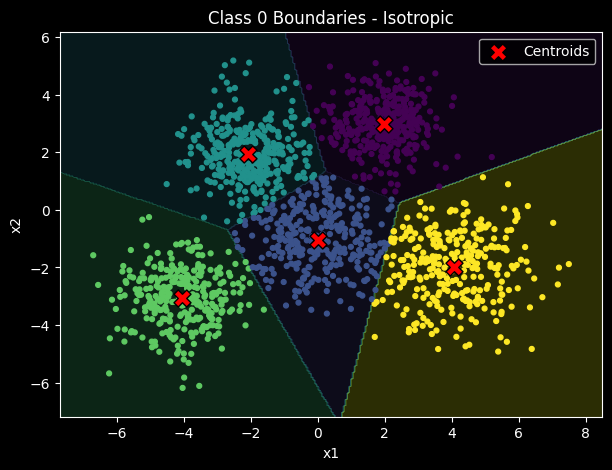

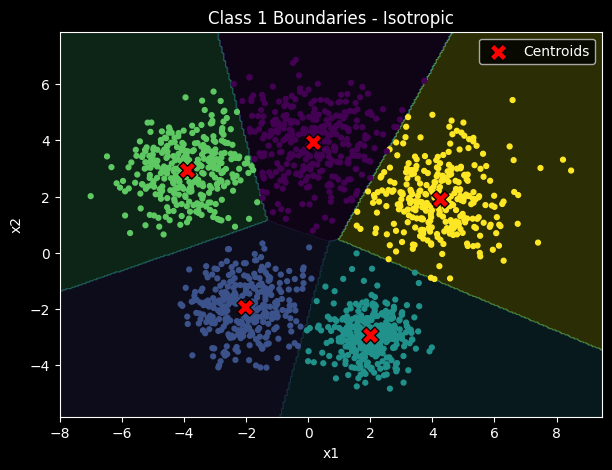

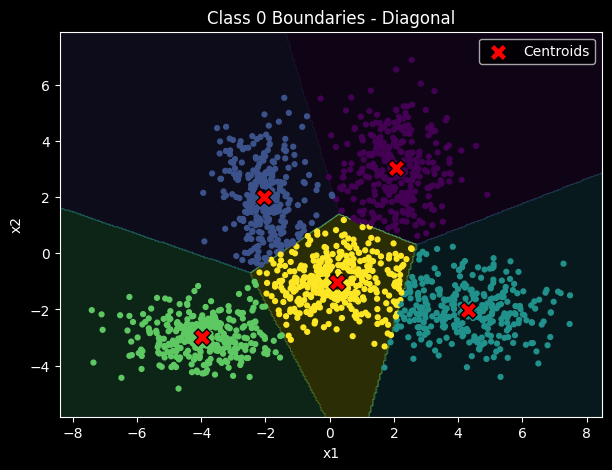

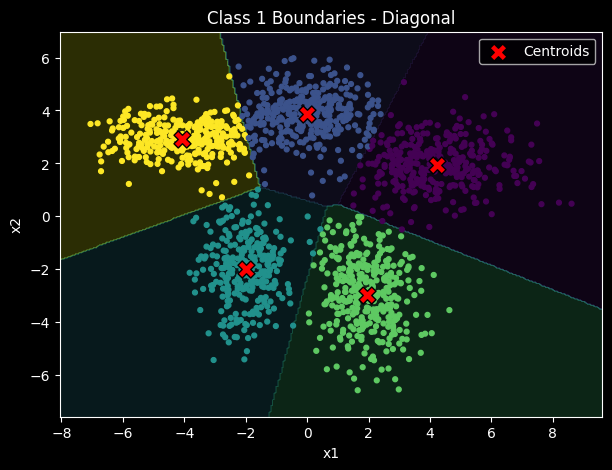

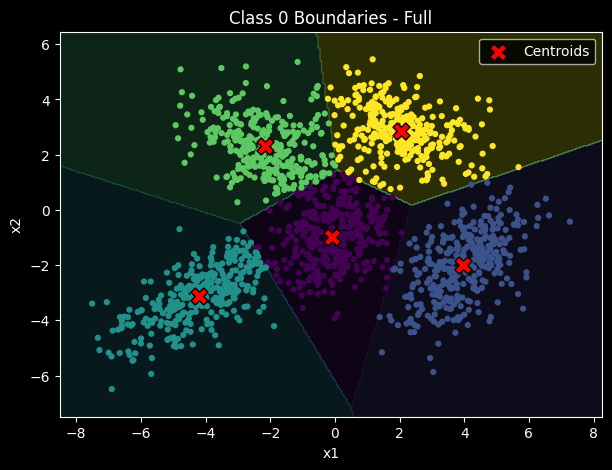

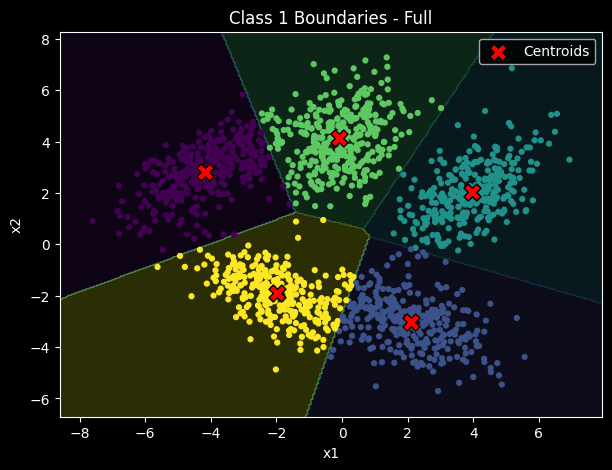

In [80]:
for covariance_name, covariances in covariance_types.items():

    X0, _ = generate_gmm_data(means_0, covariances, N)
    X1, _ = generate_gmm_data(means_1, covariances, N)

    X0_train, _ = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, _ = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    model0 = KMeans(
        n_clusters=K, random_state=42, n_init=10
    ).fit(X0_train)

    model1 = KMeans(
        n_clusters=K, random_state=42, n_init=10
    ).fit(X1_train)

    plot_kmeans_boundaries(
        X0_train, model0,
        f"Class 0 Boundaries - {covariance_name}"
    )

    plot_kmeans_boundaries(
        X1_train, model1,
        f"Class 1 Boundaries - {covariance_name}"
    )

In [81]:
for covariance_name, covariances in covariance_types.items():

    X0, _ = generate_gmm_data(means_0, covariances, N)
    X1, _ = generate_gmm_data(means_1, covariances, N)

    X0_train, X0_test = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, X1_test = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    model0 = KMeans(
        n_clusters=K, random_state=42, n_init=10
    ).fit(X0_train)

    model1 = KMeans(
        n_clusters=K, random_state=42, n_init=10
    ).fit(X1_train)

    X_test = np.vstack([X0_test, X1_test])

    y_test = np.concatenate([
        np.zeros(len(X0_test), dtype=int),
        np.ones(len(X1_test), dtype=int)
    ])

    d0 = calculate_distortion(X_test, model0)
    d1 = calculate_distortion(X_test, model1)

    y_pred = (d1 < d0).astype(int)

    accuracy = accuracy_score(y_test, y_pred)

    print("\nCovariance:", covariance_name)

    print("Class 0 test average distortion:",
          round(np.mean(d0[y_test == 0]), 4))

    print("Class 1 test average distortion:",
          round(np.mean(d1[y_test == 1]), 4))

    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))


Covariance: Isotropic
Class 0 test average distortion: 1.983
Class 1 test average distortion: 1.8009
Accuracy: 81.88 %
Confusion matrix:
[[328  72]
 [ 73 327]]

Covariance: Diagonal
Class 0 test average distortion: 1.8632
Class 1 test average distortion: 2.0068
Accuracy: 81.62 %
Confusion matrix:
[[321  79]
 [ 68 332]]

Covariance: Full
Class 0 test average distortion: 1.9798
Class 1 test average distortion: 2.0654
Accuracy: 80.62 %
Confusion matrix:
[[312  88]
 [ 67 333]]
